## 1. Import Libraries

In [26]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

## 2. Load the Karate Club Graph and Build the Modularity Matrix


In [27]:
G = nx.karate_club_graph()
nodes = sorted(G.nodes())
n,m = G.number_of_nodes() , G.number_of_edges()

A = nx.to_numpy_array(G , nodelist=nodes , weight=None)
k = A.sum(axis=1)
B = A - np.outer(k,k)/(2*m)

## 3. Helper Function: Leading Eigenvalue and Eigenvector

In [28]:
def leading_eigenpair(M):
    vals , vecs = np.linalg.eigh(M)
    return vals[-1], vecs[:,-1]

## 4. Helper Function: Modularity Score of a Partition

In [29]:
def modularity(communities):
    label = np.zeros(n, dtype=int)
    for c , C in enumerate(communities):
        label[C] = c
    same = label[:,None] == label[None,:]
    return (B*same).sum()/(2*m)

## 5. Initialise Communities, History and Queue

- `communities = [list(nodes)]` : start with all nodes in one single community
- `history = [[list(nodes)]]` : record of the partition at each iteration (iteration 0 = whole graph)
- `queue = [list(nodes)]` : communities that still need to be tried for splitting

In [30]:
communities = [list(nodes)]
history = [[list(nodes)]]
queue = [list(nodes)]

## 6. Repeatedly Split Communities Using the Leading Eigenvector

In [31]:
while queue:
    C = queue.pop(0)
    BC = B[np.ix_(C,C)]
    lam , u = leading_eigenpair(BC)

    if lam <= 1e-8:
        continue

    C_plus = [C[i] for i in range(len(C)) if u[i] > 0]
    C_minus = [C[i] for i in range(len(C)) if u[i] <= 0]
    if not C_plus or not C_minus:
        continue
    communities.remove(C)
    communities += [C_plus , C_minus]
    queue += [C_plus , C_minus]

    history.append([c[:] for c in communities])

print(f"\n{len(communities)} communities")
for C in sorted(communities, key=min):
    print(sorted(C))
    


5 communities
[0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
[4, 5, 6, 10, 16]
[8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
[11]
[24, 25, 27, 28, 31]


## 7. Compute Centrality Metrics Inside Each Community at Every Iteration

In [32]:
def community_metrics(parts):
    out = {"degree": {}, "betweenness": {}, "closeness": {}, "clustering": {}}
    for C in parts:
        H = G.subgraph(C) 
        out["degree"].update(nx.degree_centrality(H) if len(C) > 1 else {C[0]: 0.0})
        out["betweenness"].update(nx.betweenness_centrality(H))
        out["closeness"].update(nx.closeness_centrality(H))
        out["clustering"].update(nx.clustering(H))
    return out


metrics = {t: community_metrics(parts) for t, parts in enumerate(history)} 

M = {name: np.array([[metrics[t][name][i] for t in metrics] for i in nodes])
     for name in ["degree", "betweenness", "closeness", "clustering"]}

for name in ["degree", "betweenness", "closeness"]:
    top = np.argsort(-M[name].mean(axis=1), kind="stable")[:5]
    print(f"{name:12s} : {top.tolist()}")


degree       : [0, 33, 1, 32, 3]
betweenness  : [33, 0, 31, 32, 24]
closeness    : [0, 33, 1, 32, 3]


## 8. Plot How Each Metric Changes Across Iterations

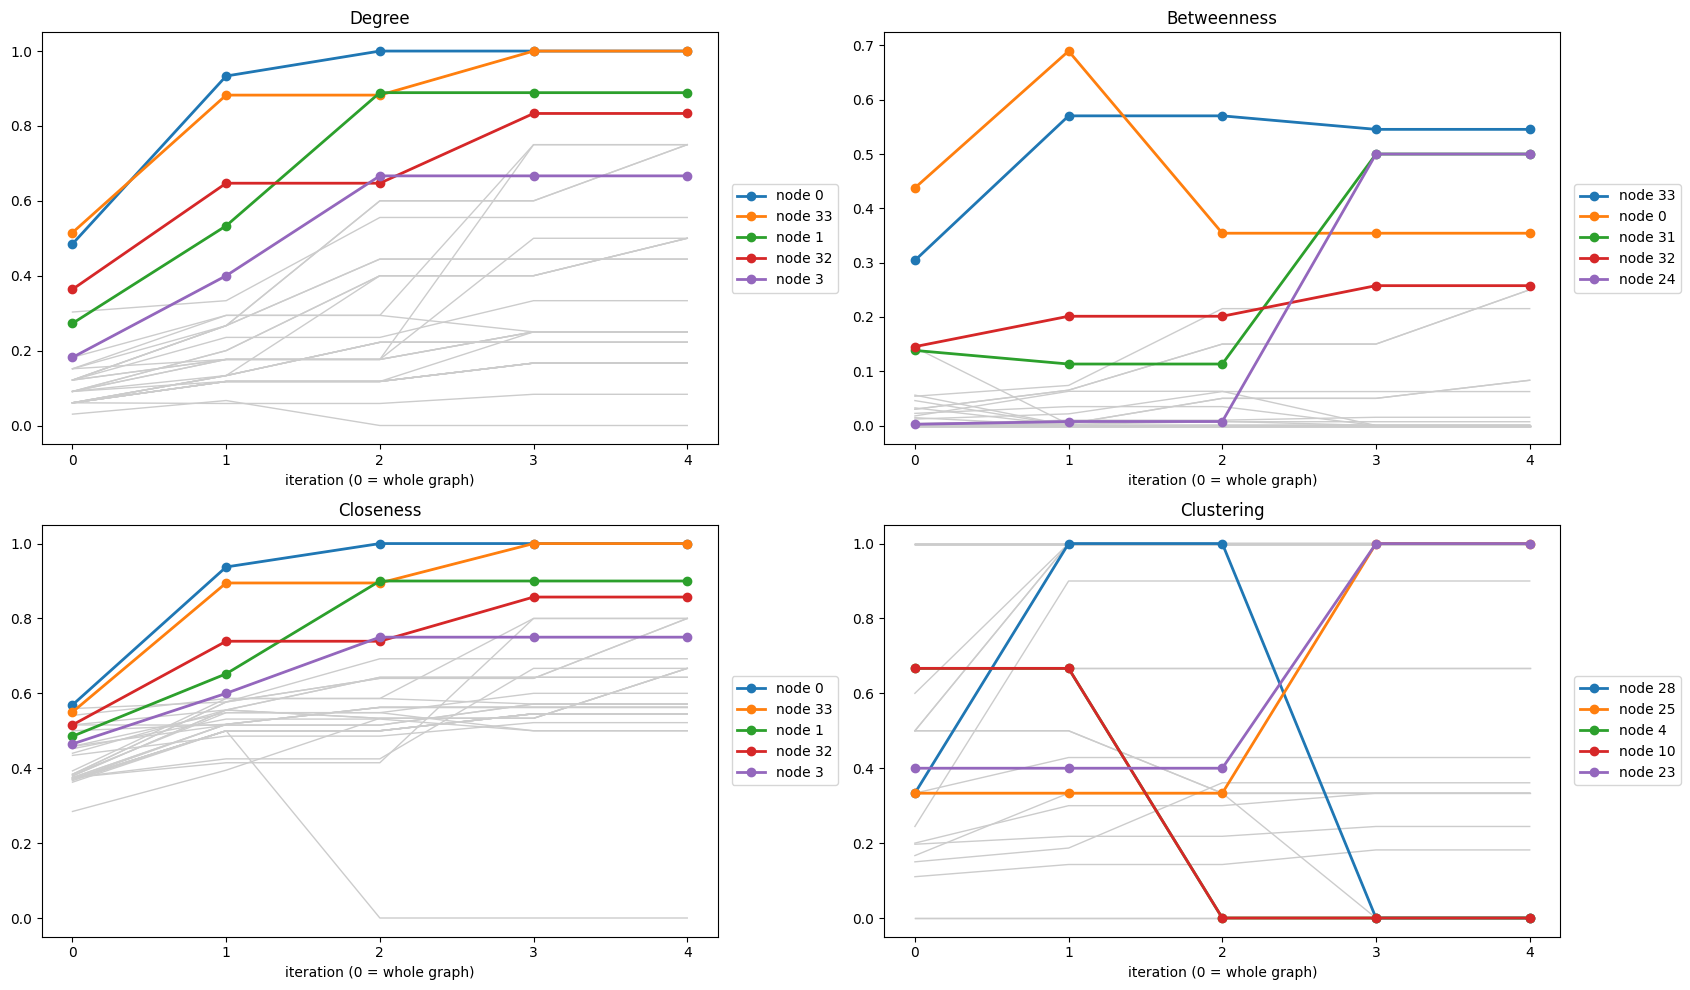

In [33]:
x = list(metrics.keys())
fig, axes = plt.subplots(2, 2, figsize=(17, 10))

for ax, (name, arr) in zip(axes.ravel(), M.items()):
    score = arr.std(axis=1) if name == "clustering" else arr.mean(axis=1)
    top = np.argsort(-score, kind="stable")[:5]
    for i in nodes:
        ax.plot(x, arr[i], color="0.8", lw=1)
    for i in top:
        ax.plot(x, arr[i], marker="o", lw=2, label=f"node {i}")
    ax.set_title(name.capitalize())
    ax.set_xlabel("iteration (0 = whole graph)")
    ax.set_xticks(x)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))

fig.tight_layout()
plt.show()

## 9. Draw and Save the Network Partition at Each Iteration

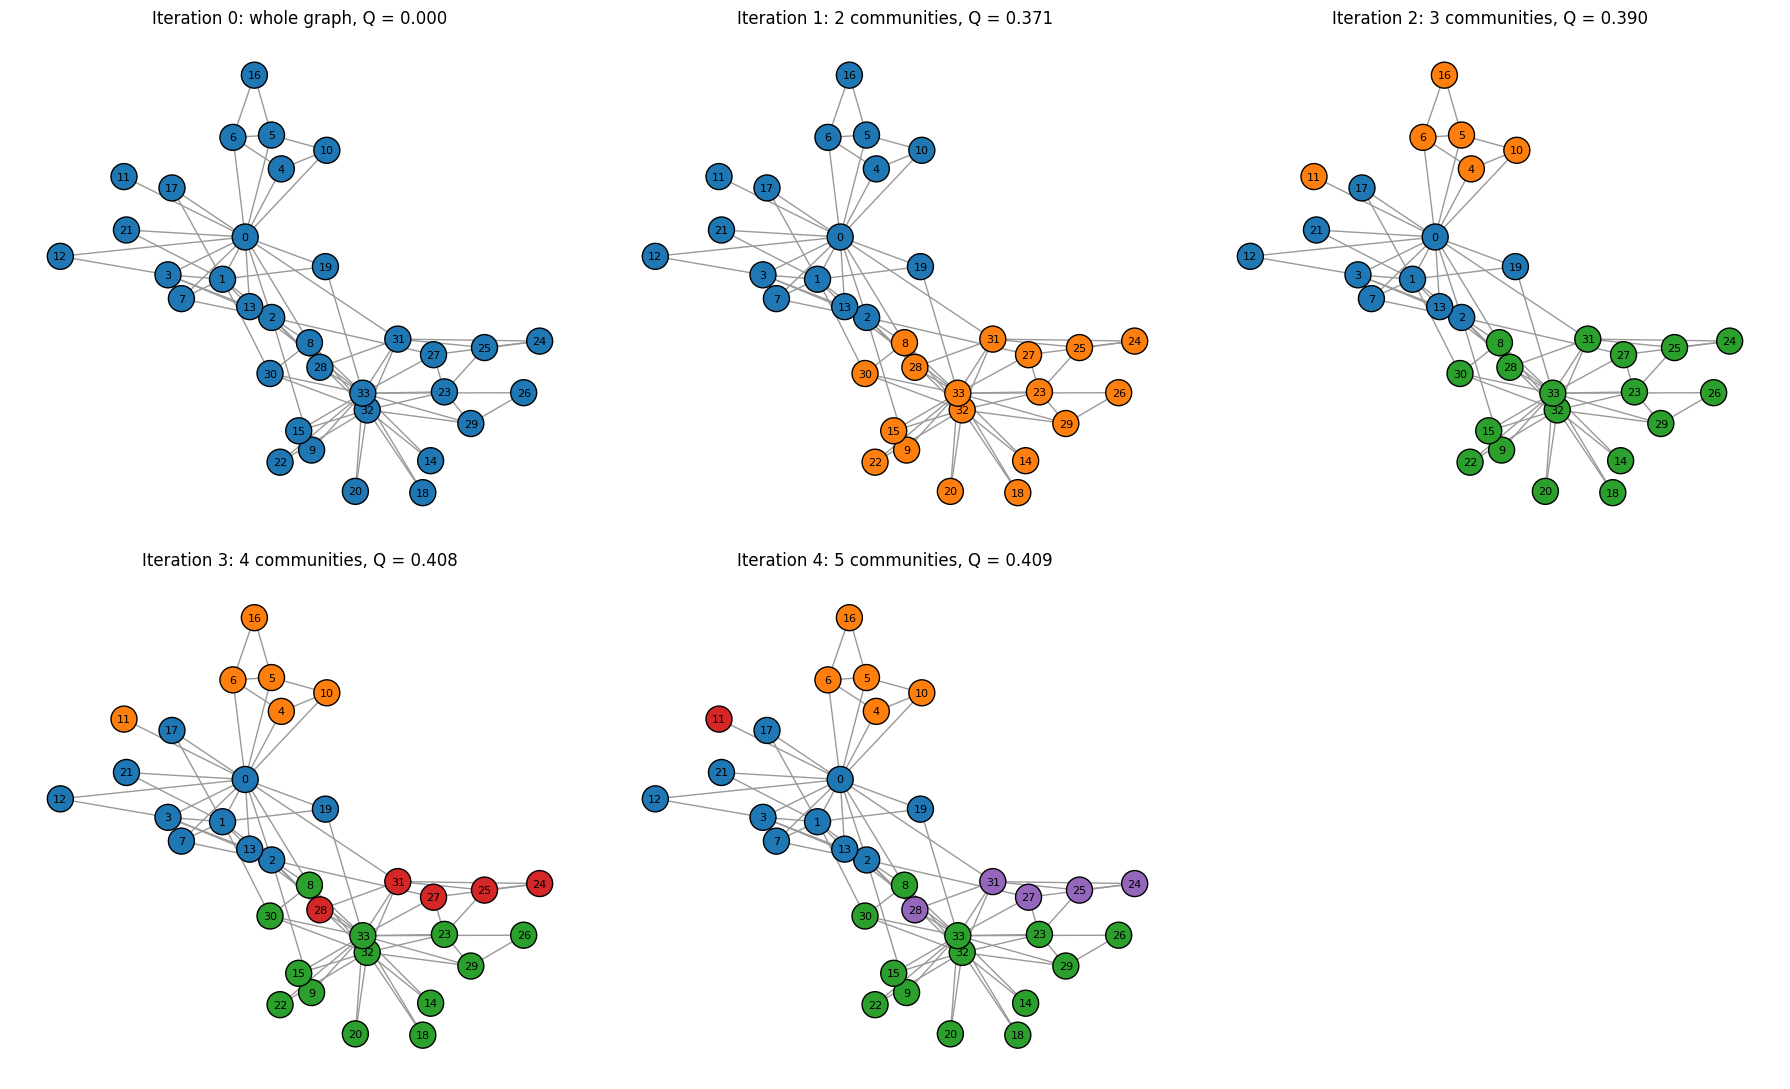

In [34]:
pos = nx.spring_layout(G, seed=42)
palette = plt.cm.tab10.colors

ncols = 3
nrows = int(np.ceil(len(history) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5.5 * nrows))
axes = axes.ravel()

for t, (parts, ax) in enumerate(zip(history, axes)):
    colour = {}
    for c, C in enumerate(sorted(parts, key=min)):
        for v in C:
            colour[v] = palette[c % len(palette)]
    nx.draw(G, pos, ax=ax, nodelist=nodes, node_color=[colour[v] for v in nodes],
            with_labels=True, node_size=350, font_size=8, edgecolors="black", edge_color="0.6")
    q = round(modularity(parts), 3) + 0.0 
    label = "whole graph" if t == 0 else f"{len(parts)} communities"
    ax.set_title(f"Iteration {t}: {label}, Q = {q:.3f}")

for ax in axes[len(history):]:
    ax.axis("off")
fig.tight_layout()
plt.show()

## 10. Discussion: Central Nodes and the Effect of Community Structure

**Nodes that stay central:** Nodes 0 and 33 stay in the top five for degree, closeness and betweenness at every split. Nodes 32 and 1 also stay in the top five for degree. These nodes are the hubs of their communities, so splitting the graph does not remove many of their neighbours. Node 33 keeps 12 of its 17 neighbours and node 0 keeps 9 of its 16 in their final communities, and inside those communities both end up with a degree score of 1.0 (linked to every other member).

**Effect of community structure:**
- **Scores rise as communities get smaller.** Degree and closeness are measured inside each community, so they go up even if a node itself has not changed. Average degree grows to 0.42 and average closeness rises to 0.64, so the scores are best read as rankings within a community.
- **Bridge nodes lose importance.** Node 2 has high betweenness in the whole graph (0.14), but it drops to about 0 after the first split because 5 of its 10 neighbours (8, 9, 27, 28, 32) go to the other community. Node 0 shows a similar effect: its betweenness rises to 0.69 after the first split, then falls to 0.35 when its community splits, because it was the only link between {4, 5, 6, 10, 11, 16} and the rest.
- **Small communities create new local leaders.** In {24, 25, 27, 28, 31}, node 27 is linked only to 24 and node 28 only to 31, so nodes 24 and 31 hold the group together. Their betweenness jumps from 0.01 to 0.50 and from 0.11 to 0.50.
- **Clustering changes the most.** A split cuts every triangle that crosses a community boundary. Nodes 4 and 10 fall to 0 once node 0 is in another community, since all their triangles went through node 0, and node 28 goes to 1.0 and then to 0 as its neighbours are moved between communities.